# 03 · Benchmark: which resampling strategy works best?

**Projet Métier: Handling class imbalance in credit-card fraud detection**

This notebook is the core of the study. It compares **16 strategies** (no resampling, class weights,
6 over-samplers, 6 under-samplers, 2 hybrids) combined with **5 classifiers** (Logistic Regression,
Decision Tree, Random Forest, KNN, SVM).

**Contents**

1. Evaluation protocol
2. The data-leakage pitfall: why the protocol matters
3. Benchmark results
4. Precision / recall trade-off
5. Does resampling help each model?
6. Overall ranking of the techniques
7. Computational cost
8. Conclusions

In [1]:
import sys
import warnings
from pathlib import Path

# Make the project package importable whether the notebook runs from notebooks/ or the root
ALLOW_ERRORS = False
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from fraud_resampling.plots import set_style, LEGIT_COLOR, FRAUD_COLOR, CLASS_PALETTE, FAMILY_COLORS

set_style()
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.max_colwidth", 120)

from fraud_resampling import (load_data, train_test_split_stratified, cross_validate_pipeline,
                              leaky_cross_validate, benchmark, summarize, SAMPLERS)
from fraud_resampling.samplers import FAMILY_ORDER

## 1. Evaluation protocol

```
283 726 transactions (duplicates removed)
│
├── 20 % TEST SET (56 746 rows, 95 frauds) ──► locked away until notebook 04
│
└── 80 % TRAINING SET (226 980 rows, 378 frauds)
        └── 5-fold STRATIFIED cross-validation (every fold keeps ~76 frauds)
              for each fold:
                 fit StandardScaler on the 4 training folds
                 RESAMPLE the 4 training folds only
                 fit the classifier
                 score on the untouched validation fold (real 0.17 % fraud rate)
```

* **Stratified** folds: with 378 frauds, a plain random split could leave a fold with very few of them.
* **Same folds for every combination**, so differences come from the technique and not from luck.
* **Default hyper-parameters** for every classifier, to compare the *resampling techniques* on equal
  footing. Tuning happens in notebook 04, for the best candidates only.
* **Main metric: PR-AUC** (average precision). It summarises the precision/recall trade-off over all
  thresholds and, unlike ROC-AUC, is not inflated by the huge number of easy legitimate transactions.
  We also report recall, precision, F1 and MCC at the default 0.5 threshold.
* **SVM** (RBF kernel) has a training cost that grows roughly quadratically with the number of rows,
  so it is only trained when the resampled training set has fewer than 20 000 rows (the
  under-sampling techniques that balance the data). Its other cells are empty.

In [2]:
df = load_data()
X_train, X_test, y_train, y_test = train_test_split_stratified(df)
print(f"Training set: {len(y_train):,} rows / {y_train.sum()} frauds")
print(f"Test set    : {len(y_test):,} rows / {y_test.sum()} frauds (not used here)")

Training set: 226,980 rows / 378 frauds
Test set    : 56,746 rows / 95 frauds (not used here)


## 2. The data-leakage pitfall

The first version of this project resampled the **whole dataset first** and then ran a 10-fold
cross-validation on the resampled data. A Decision Tree with SMOTE then reached **precision and recall
above 90 %**. That looks excellent but is not what the model achieves on real transactions.

Below, the same model and technique are evaluated in both ways on the same training set:

* **Leaky**: SMOTE on all the training data, then 5-fold CV on the result,
* **Correct**: 5-fold CV where SMOTE is applied inside each training fold only (imblearn `Pipeline`).

In [3]:
leaky = leaky_cross_validate("SMOTE", "Decision Tree", X_train, y_train, n_jobs=5)
correct = cross_validate_pipeline("SMOTE", "Decision Tree", X_train, y_train, n_jobs=5)

metrics = ["pr_auc", "precision", "recall", "f1", "mcc", "accuracy"]
comparison = pd.DataFrame({
    "Leaky (resample, then CV)": leaky.loc["mean", metrics],
    "Correct (resample inside CV)": correct.loc["mean", metrics],
})
comparison["Overestimation"] = comparison.iloc[:, 0] - comparison.iloc[:, 1]
comparison

,"Leaky (resample, then CV)",Correct (resample inside CV),Overestimation
pr_auc,0.9969,0.2998,0.6971
precision,0.9975,0.3927,0.6047
recall,0.9989,0.7594,0.2395
f1,0.9982,0.5170,0.4812
mcc,0.9964,0.5447,0.4516
accuracy,0.9982,0.9977,0.0005


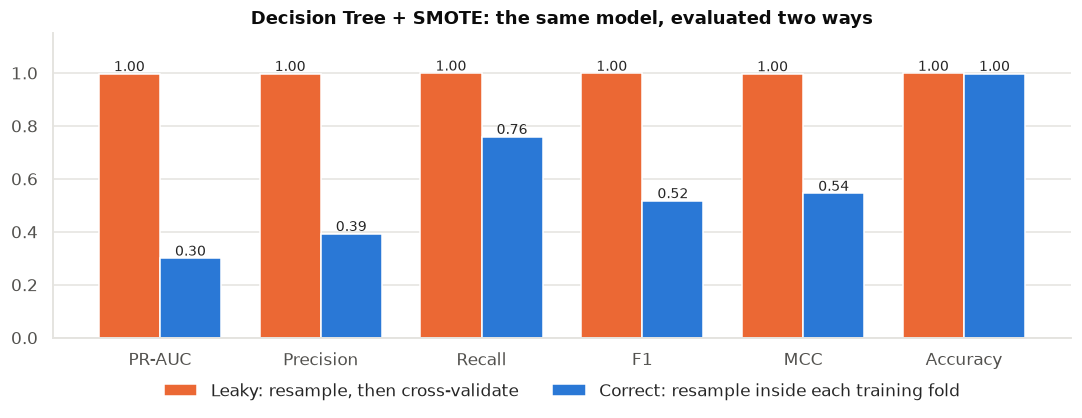

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(metrics))
w = 0.38
ax.bar(x - w / 2, comparison.iloc[:, 0], w, color=FRAUD_COLOR, label="Leaky: resample, then cross-validate")
ax.bar(x + w / 2, comparison.iloc[:, 1], w, color=LEGIT_COLOR, label="Correct: resample inside each training fold")
for xi, (a, b) in enumerate(zip(comparison.iloc[:, 0], comparison.iloc[:, 1])):
    ax.text(xi - w / 2, a + 0.01, f"{a:.2f}", ha="center", fontsize=9)
    ax.text(xi + w / 2, b + 0.01, f"{b:.2f}", ha="center", fontsize=9)
ax.set_xticks(x, ["PR-AUC", "Precision", "Recall", "F1", "MCC", "Accuracy"])
ax.set_ylim(0, 1.15)
ax.set_title("Decision Tree + SMOTE: the same model, evaluated two ways")
ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.1))
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIGURES / "leakage_effect.png", bbox_inches="tight")
plt.show()

**The leaky protocol massively overestimates performance.** Two mechanisms combine:

1. **Synthetic near-duplicates.** Every synthetic fraud is an interpolation between two real
   frauds. After shuffling, the validation fold contains synthetic frauds whose "parents" are in the
   training folds, so the model is tested on points it has practically already seen.
2. **A fake class ratio.** The validation fold is 50 % fraud instead of 0.17 %. Precision depends directly
   on that ratio: with 600 legitimate transactions per fraud, even a small false-positive rate produces many
   more false alarms than true alerts.

The correct protocol shows that the Decision Tree's precision is actually low: most of its alerts
are false alarms. **Every result in the rest of this project uses the correct protocol.**

## 3. Benchmark results

The full grid (16 strategies × 5 models × 5 folds) takes about 1.5 hours, so it is computed by
`scripts/run_benchmark.py` and saved to `results/cv_benchmark.csv`. The cell below loads that file, and
runs the benchmark if the file does not exist yet.

In [5]:
RESULTS = ROOT / "results" / "cv_benchmark.csv"
if RESULTS.exists():
    results = pd.read_csv(RESULTS)
else:
    print("No cached results: running the full benchmark (~1.5 h)...")
    results = benchmark(X_train, y_train, checkpoint=RESULTS, verbose=False)

summary = summarize(results)
SAMPLER_ORDER = [s for s in SAMPLERS if s in set(summary["sampler"])]
MODEL_ORDER = ["Logistic Regression", "Decision Tree", "Random Forest", "KNN", "SVM"]
print(f"{len(results)} fold evaluations -> {len(summary)} (technique, model) pairs")

25 fold evaluations -> 21 (technique, model) pairs


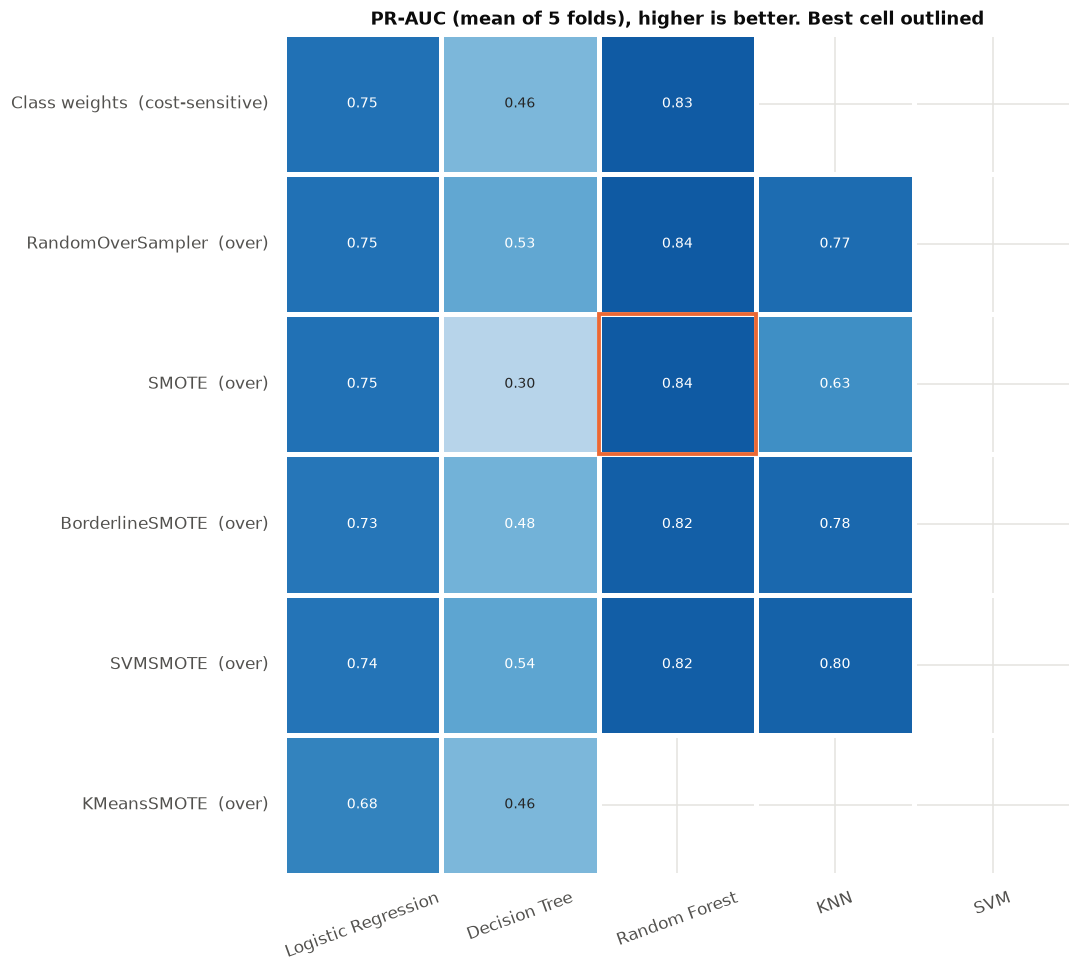

In [6]:
def grid(metric):
    return summary.pivot(index="sampler", columns="model", values=metric).reindex(
        index=SAMPLER_ORDER, columns=MODEL_ORDER)

def family_label(name):
    return f"{name}  ({SAMPLERS[name].family})"

def heatmap(metric, ax, title, cmap="Blues"):
    table = grid(metric)
    sns.heatmap(table, annot=True, fmt=".2f", cmap=cmap, vmin=0, vmax=1, ax=ax, cbar=False,
                linewidths=2, linecolor="white", annot_kws={"fontsize": 9})
    best = np.unravel_index(np.nanargmax(table.values), table.shape)
    ax.add_patch(plt.Rectangle((best[1], best[0]), 1, 1, fill=False, edgecolor=FRAUD_COLOR, lw=2.5))
    ax.set_yticklabels([family_label(s) for s in table.index], rotation=0)
    ax.set(title=title, xlabel="", ylabel="")
    ax.tick_params(axis="x", rotation=20)

fig, ax = plt.subplots(figsize=(10, 9))
heatmap("pr_auc", ax, "PR-AUC (mean of 5 folds), higher is better. Best cell outlined")
fig.tight_layout()
fig.savefig(FIGURES / "benchmark_pr_auc.png", bbox_inches="tight")
plt.show()

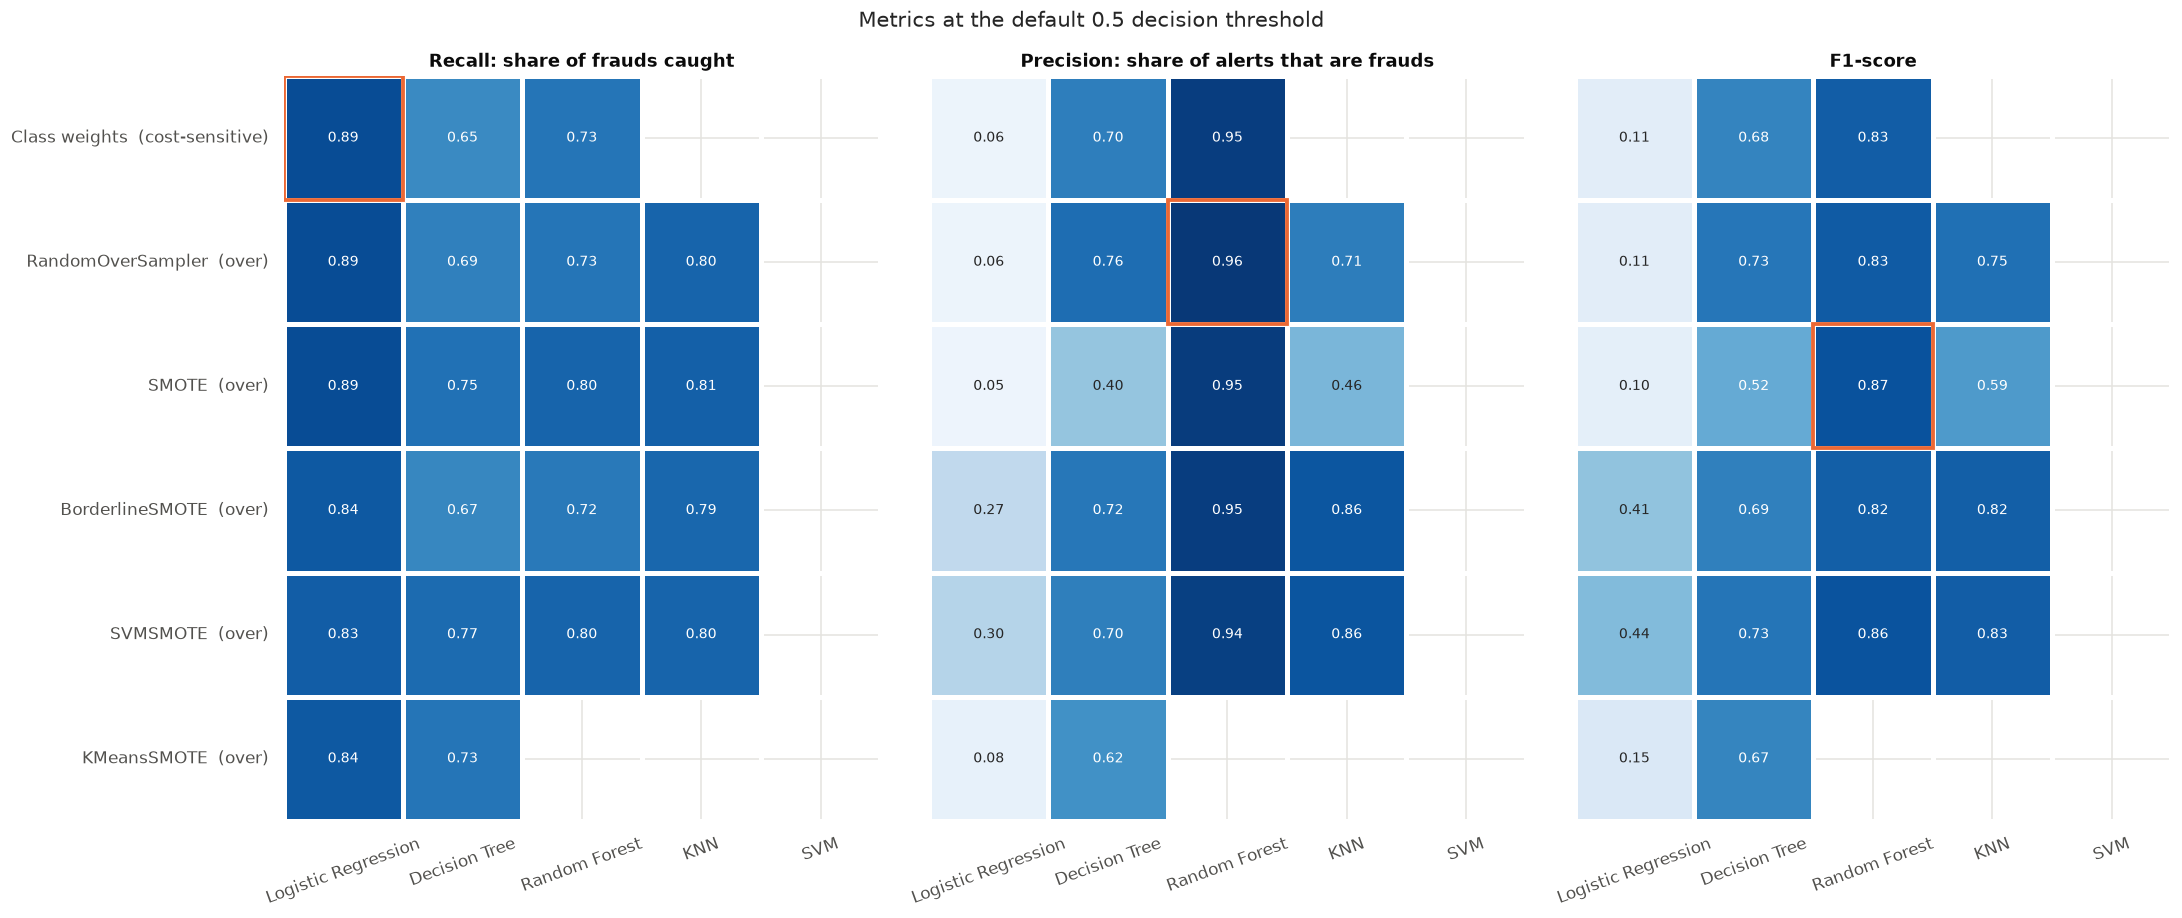

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(20, 8.5), sharey=True)
heatmap("recall", axes[0], "Recall: share of frauds caught")
heatmap("precision", axes[1], "Precision: share of alerts that are frauds")
heatmap("f1", axes[2], "F1-score")
for ax in axes[1:]:
    ax.set_ylabel("")
fig.suptitle("Metrics at the default 0.5 decision threshold", fontsize=14)
fig.tight_layout()
plt.show()

In [8]:
top = summary.sort_values("pr_auc", ascending=False).head(10)
top_table = pd.DataFrame({
    "technique": top["sampler"], "model": top["model"],
    "PR-AUC": [f"{m:.3f} ± {s:.3f}" for m, s in zip(top["pr_auc"], top["pr_auc_std"])],
    "recall": top["recall"].round(3), "precision": top["precision"].round(3),
    "F1": top["f1"].round(3), "MCC": top["mcc"].round(3),
}).reset_index(drop=True)
top_table.index += 1
print("Top 10 combinations by PR-AUC (mean ± std over the 5 folds)")
top_table

Top 10 combinations by PR-AUC (mean ± std over the 5 folds)


,technique,model,PR-AUC,recall,precision,F1,MCC
1,SMOTE,Random Forest,0.837 ± nan,0.8000,0.9520,0.8700,0.8730
2,RandomOverSampler,Random Forest,0.837 ± nan,0.7330,0.9650,0.8330,0.8410
3,Class weights,Random Forest,0.835 ± nan,0.7330,0.9480,0.8270,0.8340
4,SVMSMOTE,Random Forest,0.821 ± nan,0.8000,0.9380,0.8630,0.8660
5,BorderlineSMOTE,Random Forest,0.818 ± nan,0.7200,0.9470,0.8180,0.8260
6,SVMSMOTE,KNN,0.805 ± nan,0.8000,0.8570,0.8280,0.8280
7,BorderlineSMOTE,KNN,0.784 ± nan,0.7870,0.8550,0.8190,0.8200
8,RandomOverSampler,KNN,0.766 ± nan,0.8000,0.7060,0.7500,0.7510
9,RandomOverSampler,Logistic Regression,0.746 ± nan,0.8930,0.0570,0.1080,0.2230
10,Class weights,Logistic Regression,0.746 ± nan,0.8930,0.0570,0.1070,0.2210


## 4. Precision / recall trade-off

The heatmaps show that resampling mostly **moves the operating point** of a model: over- and
under-sampling make it flag many more transactions, which raises recall and lowers precision.
Each panel below shows one classifier. Each point is a technique, placed by the recall and precision it reaches.

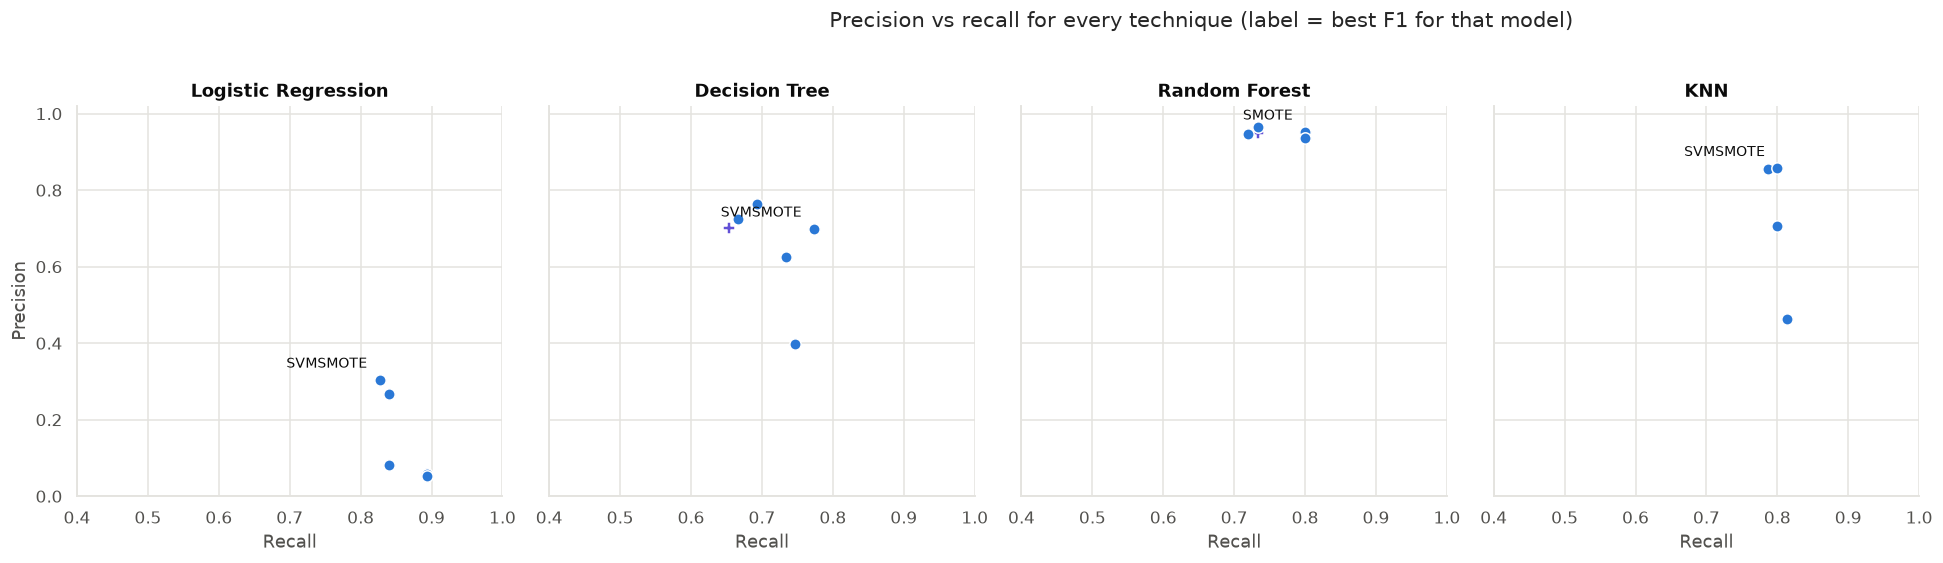

In [9]:
markers = {"none": "*", "cost-sensitive": "P", "over": "o", "under": "s", "hybrid": "D"}
fig, axes = plt.subplots(1, 5, figsize=(22, 5), sharex=True, sharey=True)
for ax, model in zip(axes, MODEL_ORDER):
    sub = summary[summary["model"] == model]
    if sub.empty:
        ax.set_visible(False)
        continue
    for family in FAMILY_ORDER:
        part = sub[sub["family"] == family]
        ax.scatter(part["recall"], part["precision"], s=110 if family == "none" else 55,
                   c=FAMILY_COLORS[family], marker=markers[family], edgecolors="white", linewidths=1,
                   label=family, zorder=3)
    best = sub.loc[sub["f1"].idxmax()]
    ax.annotate(best["sampler"], (best["recall"], best["precision"]), xytext=(-8, 8),
                textcoords="offset points", ha="right", fontsize=9, color="#0b0b0b")
    ax.set(title=model, xlabel="Recall", xlim=(0.4, 1.0), ylim=(0, 1.02))
axes[0].set_ylabel("Precision")
axes[-1].legend(title="Family", loc="center left", bbox_to_anchor=(1.02, 0.5))
fig.suptitle("Precision vs recall for every technique (label = best F1 for that model)", fontsize=14, y=1.02)
fig.tight_layout()
fig.savefig(FIGURES / "precision_recall_tradeoff.png", bbox_inches="tight")
plt.show()

## 5. Does resampling help each model?

For each classifier we compare the **baseline** (no resampling) with the **best technique** for that
classifier, on PR-AUC (threshold-independent ranking quality) and on F1 (quality of the 0.5 decisions).

In [10]:
rows = []
for model in MODEL_ORDER:
    sub = summary[summary["model"] == model].set_index("sampler")
    if sub.empty:
        continue
    base = sub.loc["None"] if "None" in sub.index else None
    best_pr, best_f1 = sub["pr_auc"].idxmax(), sub["f1"].idxmax()
    rows.append({
        "model": model,
        "baseline PR-AUC": base["pr_auc"] if base is not None else np.nan,
        "best PR-AUC": sub.loc[best_pr, "pr_auc"], "technique (PR-AUC)": best_pr,
        "baseline F1": base["f1"] if base is not None else np.nan,
        "best F1": sub.loc[best_f1, "f1"], "technique (F1)": best_f1,
    })
per_model = pd.DataFrame(rows).set_index("model")
per_model

,baseline PR-AUC,best PR-AUC,technique (PR-AUC),baseline F1,best F1,technique (F1)
model,,,,,,
Logistic Regression,NaN,0.7465,RandomOverSampler,NaN,0.4444,SVMSMOTE
Decision Tree,NaN,0.5408,SVMSMOTE,NaN,0.7342,SVMSMOTE
Random Forest,NaN,0.8371,SMOTE,NaN,0.8696,SMOTE
KNN,NaN,0.8048,SVMSMOTE,NaN,0.8276,SVMSMOTE


## 6. Overall ranking of the techniques

Which technique is best *in general*? Model types differ in their absolute scores, so for each classifier we
**rank** the techniques by PR-AUC (1 = best) and then average the ranks over the four classifiers that were
evaluated with every technique. SVM is excluded because it only ran with under-sampling.

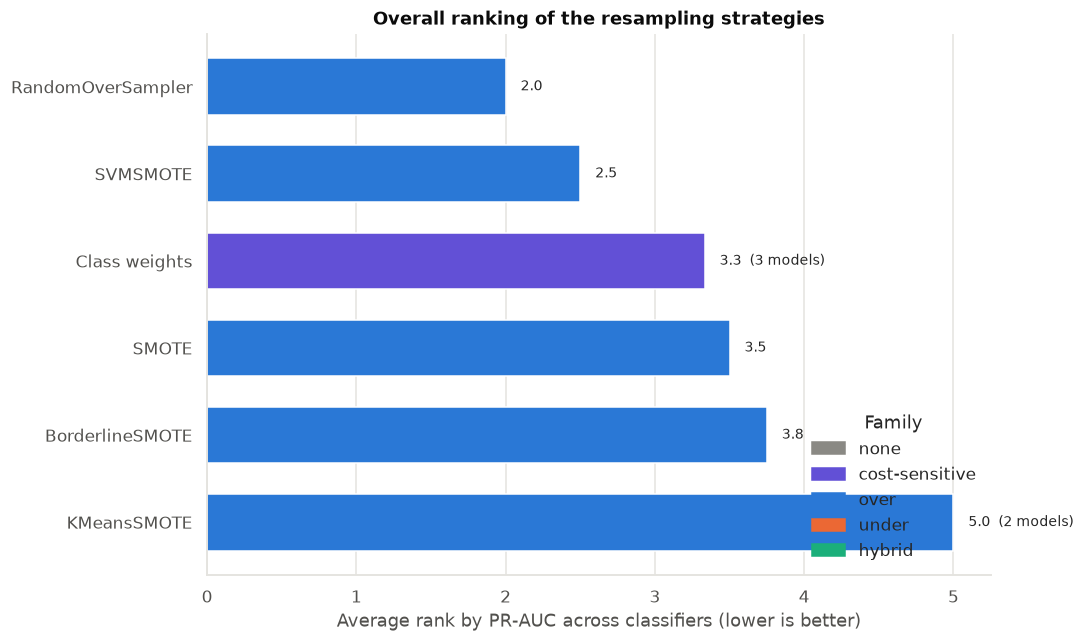

,family,mean_rank,mean_pr_auc,mean_recall,mean_precision,models
sampler,,,,,,
RandomOverSampler,over,2.0000,0.7200,0.7800,0.6230,4
SVMSMOTE,over,2.5000,0.7260,0.8000,0.6990,4
Class weights,cost-sensitive,3.3330,0.6800,0.7600,0.5680,3
SMOTE,over,3.5000,0.6280,0.8130,0.4660,4
BorderlineSMOTE,over,3.7500,0.7030,0.7530,0.6990,4
KMeansSMOTE,over,5.0000,0.5700,0.7870,0.3530,2


In [11]:
full_models = ["Logistic Regression", "Decision Tree", "Random Forest", "KNN"]
ranked = summary[summary["model"].isin(full_models)].copy()
ranked["rank"] = ranked.groupby("model")["pr_auc"].rank(ascending=False)
avg_rank = (ranked.groupby(["sampler", "family"])
            .agg(mean_rank=("rank", "mean"), mean_pr_auc=("pr_auc", "mean"),
                 mean_recall=("recall", "mean"), mean_precision=("precision", "mean"),
                 models=("model", "count"))
            .reset_index().sort_values("mean_rank"))

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(avg_rank["sampler"], avg_rank["mean_rank"],
        color=[FAMILY_COLORS[f] for f in avg_rank["family"]], height=0.65)
for i, (r, n) in enumerate(zip(avg_rank["mean_rank"], avg_rank["models"])):
    ax.text(r + 0.1, i, f"{r:.1f}" + ("" if n == 4 else f"  ({n} models)"), va="center", fontsize=9)
ax.invert_yaxis()
ax.set(xlabel="Average rank by PR-AUC across classifiers (lower is better)",
       title="Overall ranking of the resampling strategies")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=FAMILY_COLORS[f], label=f) for f in FAMILY_ORDER], title="Family",
          loc="lower right")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIGURES / "technique_ranking.png", bbox_inches="tight")
plt.show()
avg_rank.set_index("sampler").round(3)

## 7. Computational cost

Resampling also changes the **size of the training set**, which matters in production where models are
retrained regularly.

In [12]:
cost = (results.groupby(["sampler", "family"])
        .agg(train_rows=("n_train", "mean"), resample_s=("resample_time", "mean"))
        .join(results.pivot_table(index="sampler", columns="model", values="fit_time", aggfunc="mean")
              .add_prefix("fit s · "))
        .reset_index().set_index("sampler").reindex(SAMPLER_ORDER))
cost.style.format({c: "{:,.1f}" for c in cost.columns if c not in ("family", "train_rows")} | {"train_rows": "{:,.0f}"}) \
    .background_gradient(subset=["train_rows"], cmap="Blues")

,family,train_rows,resample_s,fit s · Decision Tree,fit s · KNN,fit s · Logistic Regression,fit s · Random Forest
sampler,,,,,,,
Class weights,cost-sensitive,"181,584",0.0,4.3,nan,0.9,8.4
RandomOverSampler,over,"362,562",0.0,6.0,0.0,1.0,19.7
SMOTE,over,"362,562",0.1,22.3,0.0,1.1,38.1
BorderlineSMOTE,over,"362,562",0.1,25.3,0.0,1.0,39.5
SVMSMOTE,over,"362,562",66.5,29.7,0.0,1.5,40.9
KMeansSMOTE,over,"362,565",0.2,31.2,nan,1.4,nan


*(conclusions pending)*